<a href="https://colab.research.google.com/github/LuckyMayHedgehog/Machine-Learning-data-science/blob/main/lab4-fraud-detection/ML_Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лінійна регресія - передбачає число

Логістична регресія - відповісти на питання - чи є транзакція шахрайською?

0 - ні, 1 - так

Нам не потрібно передбачити суму шахрайства, а потрібно визначити 0 чи 1

Логістична регресія бере результат математичної моделі й пропускає його через сигмоїдну функцію.

Лінійна регресія - число,

Логістична регресія - ймовірність

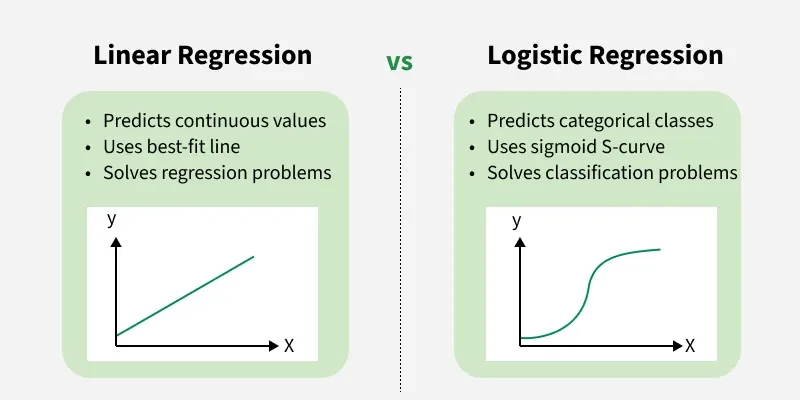

In [1]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
!pip install kagglehub --quiet


In [3]:
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download("whenamancodes/fraud-detection")

print("Шлях до датасету:", path)

print("Файли:", os.listdir(path))

csv_files = [file for file in os.listdir(path) if file.endswith(".csv")]
print("CSV:", csv_files)

file_path = os.path.join(path, csv_files[0])

df = pd.read_csv(file_path)

print("Шлях до файлу:", file_path)
print(f"Розмірність: {df.shape}")

df.head()

100%|██████████| 66.0M/66.0M [00:01<00:00, 41.3MB/s]

Extracting files...


Шлях до датасету: /root/.cache/kagglehub/datasets/whenamancodes/fraud-detection/versions/1
Файли: ['creditcard.csv']
CSV: ['creditcard.csv']
Шлях до файлу: /root/.cache/kagglehub/datasets/whenamancodes/fraud-detection/versions/1/creditcard.csv
Розмірність: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("Кількість звичайних операцій:", (df["Class"] == 0).sum())
print("Кількість шахрайських операцій:", (df["Class"] == 1).sum())

Кількість звичайних операцій: 284315
Кількість шахрайських операцій: 492


In [5]:

print("\nІнформація про датасет:")
df.info()

print("\nСтатистичний опис:")
display(df.describe())

print("\nРозподіл класів:")
print(df["Class"].value_counts())

print(df["Class"].value_counts(normalize=True) * 100)


Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000



Розподіл класів:
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [6]:
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split


In [7]:
# 1. Розділення на матрицю ознак (X) та цільову змінну (y)
X = df.drop(columns=['Class'])
y = df['Class']

# Спочатку ділимо дані, щоб уникнути витоку даних (Data Leakage) під час масштабування
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=13,
    stratify=y # однакова частка у всіх версіях
)

# 2. Масштабування ознак Amount та Time
# RobustScaler менш чутливий до викидів, ніж StandardScaler
scaler = RobustScaler()
# Через багато outliers в amount - 10, 25$.. 25000

# Навчаємо (fit) скейлер ТІЛЬКИ на тренувальних даних, а до тестових застосовуємо (transform)
X_train[['scaled_amount', 'scaled_time']] = scaler.fit_transform(X_train[['Amount', 'Time']])
X_test[['scaled_amount', 'scaled_time']] = scaler.transform(X_test[['Amount', 'Time']])

# Видаляємо оригінальні незмасштабовані стовпчики
X_train.drop(columns=['Time', 'Amount'], inplace=True)
X_test.drop(columns=['Time', 'Amount'], inplace=True)

print(f"Розмір тренувальної вибірки: {X_train.shape}")
print(f"Розмір тестової вибірки: {X_test.shape}")
print("\nРозподіл класів у тренувальному наборі:")
print(y_train.value_counts(normalize=True) * 100)

Розмір тренувальної вибірки: (227845, 30)
Розмір тестової вибірки: (56962, 30)

Розподіл класів у тренувальному наборі:
Class
0    99.827075
1     0.172925
Name: proportion, dtype: float64


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

X_raw = df.drop(columns=['Class'])
y = df['Class']

X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw, y, test_size=0.2, random_state=13, stratify=y
)

# Масштабування RobustScaler
# X_train, X_test вже готові

experiments = {

    "1. LogReg (Без обробки Time/Amount)": {
        "model": LogisticRegression(max_iter=1000, random_state=13),
        "X_train": X_tr_raw, "X_test": X_te_raw #не нормалізовані дані, алгоритм робить
        #маленькі кроки, тому навіть 1000 не вистачило
    },

    "2. LogReg (RobustScaler)": {
        "model": LogisticRegression(max_iter=1000, random_state=13),
        "X_train": X_train, "X_test": X_test
        #дані виміряно, тому модель зійшлася швидко
    },

    "3. LogReg (RobustScaler + class_weight='balanced')": {
        "model": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=13),
        "X_train": X_train, "X_test": X_test
         #За замовчуванням логістична регресія вважає кожну помилку однаково важливою
        #'balanced'- автоматично зважує штраф за помилку обернено пропорційно до частоти класів
        #тобто за шахрая модель штрафується в 500 раз сильніше ніж на звичайній транзакції
    },

    "4. Random Forest (RobustScaler, n_estimators=50)": {
        "model": RandomForestClassifier(n_estimators=50, random_state=13, n_jobs=-1),
        "X_train": X_train, "X_test": X_test
        #Замість 1 є 50 дерев рішень, виносять вердикт
    },
    "5. Random Forest (RobustScaler + class_weight='balanced')": {
        "model": RandomForestClassifier(n_estimators=50, class_weight='balanced', random_state=13, n_jobs=-1),
        "X_train": X_train, "X_test": X_test
        #а тепер balanced - значно більша вага, штраф
    }
}


results = []

for name, exp in experiments.items():
    clf = exp["model"]
    clf.fit(exp["X_train"], y_tr)

    y_pred = clf.predict(exp["X_test"])
    y_proba = clf.predict_proba(exp["X_test"])[:, 1]



    results.append({
        "Експеримент": name,
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1-Score": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_proba)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Експеримент,Precision,Recall,F1-Score,ROC-AUC
0,1. LogReg (Без обробки Time/Amount),0.9130,0.6429,0.7545,0.9263
1,2. LogReg (RobustScaler),0.8788,0.5918,0.7073,0.9602
2,3. LogReg (RobustScaler + class_weight='balanc...,0.0678,0.8367,0.1255,0.9808
3,"4. Random Forest (RobustScaler, n_estimators=50)",0.9595,0.7245,0.8256,0.9120
4,5. Random Forest (RobustScaler + class_weight=...,0.9444,0.6939,0.8000,0.9120
